# S2 enrichment: how many missing references did we recover for the core (ogbn-arxiv) articles?

**Project context:** the goal is to regenerate the abstracts of ogbn-arxiv publications ("core" articles) from their citation graph. The ogbn-arxiv dataset turned out to be missing a lot of real edges/nodes (citations to papers outside the arXiv-CS/MAG snapshot it was built from), so the full ~500GB Semantic Scholar bulk dataset was downloaded specifically to recover those missing edges (and the missing cited papers themselves) for the core articles. Every node from ogbn-arxiv is marked `core=True` in `joint_dataset/nodes.csv`; everything else is a paper discovered only via the S2 recovery step.

**This notebook answers, on the full core node set (not the test split):**
1. Does `core=True` correctly and exactly identify the ogbn-arxiv node set (Section 0)?
2. How many of a core article's real references were missing from ogbn-arxiv's own `edges.csv`, and how many did the S2 recovery step fill in (Section 3 - the headline number)?
3. Of the recovered references, how many point to papers ogbn-arxiv already had vs. brand-new papers it was missing entirely (Section 4)?
4. Did the pipeline scripts (`build_dataset.py`, `filter_ogbn_references.py`, `build_joint_dataset.py`) do this correctly, and what caps how much more could have been recovered (Section 5)?


In [1]:
import pandas as pd

ogbn_nodes = pd.read_csv("ogbn_arxiv_dataset/nodes.csv")
ogbn_edges = pd.read_csv("ogbn_arxiv_dataset/edges.csv")

papers_filtered = pd.read_parquet("s2_data/processed/papers_filtered.parquet")
references_subset = pd.read_parquet("s2_data/processed/references_subset.parquet")

joint_nodes = pd.read_csv("joint_dataset/nodes.csv")
joint_edges = pd.read_csv("joint_dataset/edges.csv")

core_ids = set(joint_nodes.loc[joint_nodes["core"], "node_id"])
print("ogbn nodes/edges:", ogbn_nodes.shape, ogbn_edges.shape)
print("s2 papers_filtered/references_subset:", papers_filtered.shape, references_subset.shape)
print("joint nodes/edges:", joint_nodes.shape, joint_edges.shape)
print("core nodes in joint:", len(core_ids))

ogbn nodes/edges: (169343, 6) (1166243, 2)
s2 papers_filtered/references_subset: (314224, 5) (2986960, 2)
joint nodes/edges: (384756, 6) (3844151, 2)
core nodes in joint: 169343


## 0. Does `core=True` exactly identify the ogbn-arxiv node set?

This has to hold exactly for "core" to mean what the project intends (the set of articles we're actually trying to regenerate abstracts for): every ogbn-arxiv mag_id must be `core=True`, and nothing else may be.

In [2]:
ogbn_mag = set(ogbn_nodes["mag_id"])
core_mag = set(joint_nodes.loc[joint_nodes["core"], "mag_id"])
noncore_mag = set(joint_nodes.loc[~joint_nodes["core"], "mag_id"])

print("ogbn-arxiv mag_ids:", len(ogbn_mag))
print("core=True mag_ids in joint_dataset:", len(core_mag))
print("ogbn mag_ids NOT marked core (should be 0):", len(ogbn_mag - core_mag))
print("core-flagged mag_ids that aren't actually ogbn-arxiv (should be 0):", len(core_mag - ogbn_mag))
print("overlap between core and non-core sets (should be 0):", len(core_mag & noncore_mag))
print("exact match core_mag == ogbn_mag:", core_mag == ogbn_mag)

ogbn-arxiv mag_ids: 169343
core=True mag_ids in joint_dataset: 169343
ogbn mag_ids NOT marked core (should be 0): 0
core-flagged mag_ids that aren't actually ogbn-arxiv (should be 0): 0
overlap between core and non-core sets (should be 0): 0
exact match core_mag == ogbn_mag: True


## 1. `ogbn_arxiv_dataset` on its own

In [3]:
print("nodes:", len(ogbn_nodes), "columns:", list(ogbn_nodes.columns))
print("edges:", len(ogbn_edges), "columns:", list(ogbn_edges.columns))
print("duplicate mag_id:", ogbn_nodes["mag_id"].duplicated().sum())
print("duplicate edges:", ogbn_edges.duplicated().sum())
print("self-loops:", (ogbn_edges["src_node_id"] == ogbn_edges["dst_node_id"]).sum())

ogbn_before_deg = ogbn_edges.groupby("src_node_id").size()
ogbn_before_full = pd.Series(0, index=ogbn_nodes["node_id"]).add(ogbn_before_deg, fill_value=0).astype(int)
print("\nout-degree over ALL ogbn nodes (full dataset, not just test split):")
print(ogbn_before_full.describe())
print("nodes with out-degree 0:", (ogbn_before_full == 0).sum())

nodes: 169343 columns: ['node_id', 'mag_id', 'title', 'abstract', 'label', 'year']
edges: 1166243 columns: ['src_node_id', 'dst_node_id']
duplicate mag_id: 0
duplicate edges: 0
self-loops: 0

out-degree over ALL ogbn nodes (full dataset, not just test split):
count    169343.000000
mean          6.886869
std           8.879428
min           0.000000
25%           1.000000
50%           4.000000
75%           9.000000
max         436.000000
dtype: float64
nodes with out-degree 0: 17440


## 2. The S2 subset on its own (`papers_filtered.parquet` / `references_subset.parquet`)

This is the raw material the enrichment pulled in: the 169,343 ogbn-arxiv papers plus every paper any of them cites *that also has an abstract in the Semantic Scholar bulk release* (see Section 5 for why that last clause matters a lot).

In [4]:
print("papers_filtered nodes:", len(papers_filtered))
print("references_subset edges:", len(references_subset))
print("duplicate mag_id:", papers_filtered["mag_id"].duplicated().sum())
print("duplicate edges:", references_subset.duplicated().sum())
print("self-loops:", (references_subset["citing_mag_id"] == references_subset["cited_mag_id"]).sum())

s2_deg = references_subset.groupby("citing_mag_id").size()
s2_full = pd.Series(0, index=papers_filtered["mag_id"]).add(s2_deg, fill_value=0).astype(int)
print("\nout-degree over ALL s2 papers_filtered nodes:")
print(s2_full.describe())
print("nodes with out-degree 0:", (s2_full == 0).sum(), "/", len(s2_full))

papers_filtered nodes: 314224
references_subset edges: 2986960
duplicate mag_id: 0


duplicate edges: 0
self-loops: 20



out-degree over ALL s2 papers_filtered nodes:
count    314224.000000
mean          9.505830
std          12.011068
min           0.000000
25%           2.000000
50%           6.000000
75%          13.000000
max         738.000000
dtype: float64
nodes with out-degree 0: 33539 / 314224


## 3. Headline metric: recovered references for core articles (full dataset, all destinations)

"Before" = out-degree of each core article in ogbn-arxiv's own `ogbn_arxiv_dataset/edges.csv` - i.e. the (incomplete) reference list ogbn-arxiv originally gave us. "After" = out-degree of the *same* core articles in `joint_dataset/edges.csv`, counting edges to **any** destination (an already-known core paper or a paper recovered only via S2) - i.e. the article's actual reference list once the S2 recovery step fills in what ogbn-arxiv was missing. This is the direct answer to "how much did the S2 enrichment recover of the core articles' missing references," computed over all 169,343 core nodes (not just the test split).

In [5]:
after_all_src = joint_edges[joint_edges["src_node_id"].isin(core_ids)]
after_all_deg = after_all_src.groupby("src_node_id").size()
after_all_full = pd.Series(0, index=ogbn_nodes["node_id"]).add(after_all_deg, fill_value=0).astype(int)

print("before - mean/median out-degree:", ogbn_before_full.mean(), "/", ogbn_before_full.median())
print("after  - mean/median out-degree:", after_all_full.mean(), "/", after_all_full.median())
print("before - nodes with out-degree 0:", (ogbn_before_full == 0).sum())
print("after  - nodes with out-degree 0:", (after_all_full == 0).sum())
print("before - nodes with out-degree > 50:", (ogbn_before_full > 50).sum())
print("after  - nodes with out-degree > 50:", (after_all_full > 50).sum())

before - mean/median out-degree: 6.886868663009395 / 4.0
after  - mean/median out-degree: 12.550592584281606 / 8.0
before - nodes with out-degree 0: 17440
after  - nodes with out-degree 0: 8675
before - nodes with out-degree > 50: 499
after  - nodes with out-degree > 50: 4284


In [6]:
# Requested table: rows = out-degree 0..50, columns = count before / count after / difference
before_counts = ogbn_before_full.value_counts()
after_counts = after_all_full.value_counts()

degree_table = pd.DataFrame({"before_enrichment": before_counts, "after_enrichment": after_counts})
degree_table = degree_table.reindex(range(51)).fillna(0).astype(int)
degree_table["difference"] = degree_table["after_enrichment"] - degree_table["before_enrichment"]
degree_table.index.name = "out_degree"
degree_table

,before_enrichment,after_enrichment,difference
out_degree,,,
0,17440,8675,-8765
1,27853,13523,-14330
2,20924,13074,-7850
3,15441,11679,-3762
4,11973,10463,-1510
5,9632,9626,-6
6,7846,8501,655
7,6770,7749,979
8,5706,6785,1079


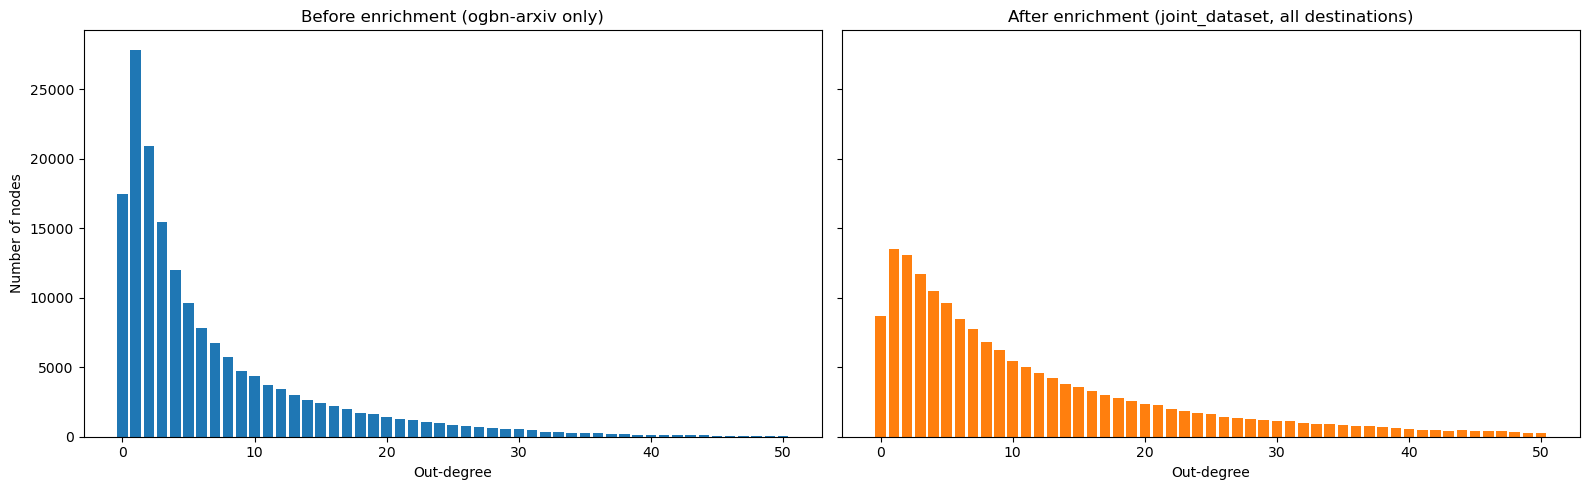

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
axes[0].bar(degree_table.index, degree_table["before_enrichment"], width=0.8)
axes[0].set_title("Before enrichment (ogbn-arxiv only)")
axes[0].set_xlabel("Out-degree")
axes[0].set_ylabel("Number of nodes")

axes[1].bar(degree_table.index, degree_table["after_enrichment"], width=0.8, color="C1")
axes[1].set_title("After enrichment (joint_dataset, all destinations)")
axes[1].set_xlabel("Out-degree")
plt.tight_layout()
plt.show()

## 4. Where do the recovered references point: already-known papers, or entirely new ones?

Splits the Section 3 recovery into two pieces: references S2 found between two *already-known* core articles (edges ogbn-arxiv's own graph was missing, even though both papers were already in the dataset), vs. references to papers ogbn-arxiv didn't contain at all (recovered only because S2 gave us the missing node too). Both counts confirm your description of the problem - ogbn-arxiv was missing both edges *and* nodes.

In [8]:
after_coredst = after_all_src[after_all_src["dst_node_id"].isin(core_ids)]
after_coredst_deg = after_coredst.groupby("src_node_id").size()
after_coredst_full = pd.Series(0, index=ogbn_nodes["node_id"]).add(after_coredst_deg, fill_value=0).astype(int)

print("after (core dst only) - mean/median out-degree:", after_coredst_full.mean(), "/", after_coredst_full.median())
print("(compare to 'before':", ogbn_before_full.mean(), "/", ogbn_before_full.median(), ")")
print("\n=> restricting destinations to core nodes hides almost all of the enrichment's effect.")

ogbn_pairs = set(zip(ogbn_edges["src_node_id"], ogbn_edges["dst_node_id"]))
coredst_pairs = set(zip(after_coredst["src_node_id"], after_coredst["dst_node_id"]))
print("\noriginal ogbn core-core edges:", len(ogbn_pairs))
print("core-core edges in joint that already existed in ogbn:", len(coredst_pairs & ogbn_pairs))
print("BRAND NEW core-core edges found only via S2:", len(coredst_pairs - ogbn_pairs))
print("(every original ogbn core-core edge is preserved: ",
      ogbn_pairs.issubset(coredst_pairs), ")")

print("\ntotal edges out of core nodes, ALL destinations (the real 'after'):", len(after_all_src))
print("of which, edges to newly-added S2-only nodes:", len(after_all_src) - len(after_coredst))

after (core dst only) - mean/median out-degree: 7.300750547704954 / 4.0
(compare to 'before': 6.886868663009395 / 4.0 )

=> restricting destinations to core nodes hides almost all of the enrichment's effect.



original ogbn core-core edges: 1166243
core-core edges in joint that already existed in ogbn: 1166243
BRAND NEW core-core edges found only via S2: 70088
(every original ogbn core-core edge is preserved:  True )

total edges out of core nodes, ALL destinations (the real 'after'): 2125355
of which, edges to newly-added S2-only nodes: 889024


## 5. Script/pipeline review: was this done correctly, and what caps the recovery?

Walking back through the pipeline (`Download_script/build_dataset.py` -> `Download_script/filter_ogbn_references.py` -> `Download_script/add_titles_years.py` -> `s2_data/build_joint_dataset.py`):

1. **`build_dataset.py` step 2** builds `papers.parquet` with `WHERE a.abstract IS NOT NULL` - a paper only survives if the S2 bulk *abstracts* dataset actually has an abstract for it. This is intentional (the pipeline is abstract-only, no full text, documented in `Download_script/README.md`, and an abstract is exactly what a core article's own regeneration target needs and what a source paper needs to be usable context) - but it means **any paper a core article cites that isn't covered by S2's abstracts dump is silently dropped from the whole pipeline**, edge and all, even though the citation itself was found.
2. **`filter_ogbn_references.py` step 4** (`papers_filtered = papers WHERE mag_id IN combined_ids`) inherits that same restriction transitively - a referenced paper only makes it into `papers_filtered.parquet`/`references_subset.parquet` if it (a) has a MAG id AND (b) has an abstract in the S2 release.
3. S2's abstract coverage is well known to be well under 100% of all papers (particularly for older / non-open-access / non-English papers) - this is the most likely reason the *reachable* new-node count (215,413 new papers) is smaller than the full ~500GB citation graph would suggest, not a bug in the scripts. This is the real ceiling on how much more could be recovered: it's bounded by S2's abstract coverage of whatever core articles cite, not by anything wrong here.
4. Everything else checks out as designed: `core=True` exactly matches the ogbn-arxiv node set (Section 0), every original ogbn core-core edge survived into `joint_dataset/edges.csv` unmodified (`issubset` check below), no duplicate nodes/edges anywhere, and the citation direction convention (`src`/`citing` cites `dst`/`cited`) is consistent across `edges.csv` and `references_subset.parquet`.

**Bottom line:** the S2 recovery step is working as intended and materially closes the gap ogbn-arxiv left - out-degree-0 core articles cut roughly in half (17,440 -> 8,675), mean references per core article nearly doubled (6.89 -> 12.55), with +215k previously-missing papers and +70k previously-missing edges between already-known core articles recovered.

In [9]:
# Final correctness re-check across all three CSV/parquet outputs
checks = {
    "ogbn nodes: no dup mag_id": not ogbn_nodes["mag_id"].duplicated().any(),
    "ogbn nodes: no dup node_id": not ogbn_nodes["node_id"].duplicated().any(),
    "joint nodes: no dup mag_id": not joint_nodes["mag_id"].duplicated().any(),
    "joint nodes: no dup node_id": not joint_nodes["node_id"].duplicated().any(),
    "joint edges: no dup (src,dst)": not joint_edges.duplicated().any(),
    "joint edges: all src ids valid": joint_edges["src_node_id"].isin(joint_nodes["node_id"]).all(),
    "joint edges: all dst ids valid": joint_edges["dst_node_id"].isin(joint_nodes["node_id"]).all(),
    "all original ogbn core-core edges preserved in joint": ogbn_pairs.issubset(
        set(zip(joint_edges["src_node_id"], joint_edges["dst_node_id"]))
    ),
    "core=True exactly matches ogbn-arxiv node set": core_mag == ogbn_mag,
}
for k, v in checks.items():
    print(("PASS" if v else "FAIL"), "-", k)

PASS - ogbn nodes: no dup mag_id
PASS - ogbn nodes: no dup node_id
PASS - joint nodes: no dup mag_id
PASS - joint nodes: no dup node_id
PASS - joint edges: no dup (src,dst)
PASS - joint edges: all src ids valid
PASS - joint edges: all dst ids valid
PASS - all original ogbn core-core edges preserved in joint
PASS - core=True exactly matches ogbn-arxiv node set
